Questions:
1. The data file contains numerical attributes that describe a letter and its corresponding class. Read the datafile “letterCG.data” and set all the numerical attributes as features.Split the data intotrain and test sets.
2. Fit a sequence of AdaBoostClassifier with varying numbersof weak learners ranging from 1 to 16, keeping the max_depth as 1. Plot the accuracy ofthe test set against the number of weak learners.Use the decision tree classifier as the base classifier.
3. Repeat step2 with max_depth set as 2.

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [12]:
df = pd.read_csv('D:\\repositories\\Machine Learning\\files\\letterCG.data',sep=" ")
df.head()

,Class,x-box,y-box,width,high,onpix,x-bar,y-bar,x2bar,y2bar,xybar,x2ybr,xy2br,x-ege,xegvy,y-ege,yegvx
0,C,4,10,5,8,2,5,7,7,10,7,6,13,1,8,4,9
1,C,3,5,4,4,2,4,8,5,7,12,9,11,1,10,2,7
2,G,5,10,6,7,3,8,7,8,8,6,7,9,2,7,5,10
3,C,5,9,6,7,4,3,8,6,7,12,10,13,1,9,3,7
4,G,4,8,5,6,3,6,6,7,6,10,7,12,2,9,4,9


In [51]:
X = df.drop('Class',axis=1)
y = df['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [52]:
n_estimator = range(1,17)
acc_depth_1 = []
for n in n_estimator:
    dt = DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=1,random_state=42)
    ada = AdaBoostClassifier(estimator=dt,n_estimators=n,learning_rate=1,random_state=42)
    ada.fit(X_train, y_train)
    preds = ada.predict(X_test)
    acc_depth_1.append(accuracy_score(y_test,preds))


In [53]:
n_estimator = range(1,17)
acc_depth_2 = []
for n in n_estimator:
    dt = DecisionTreeClassifier(criterion='gini',splitter='best',max_depth=2,random_state=42)
    ada = AdaBoostClassifier(estimator=dt,n_estimators=n,learning_rate=1,random_state=42)
    ada.fit(X_train, y_train)
    preds = ada.predict(X_test)
    acc_depth_2.append(accuracy_score(y_test,preds))

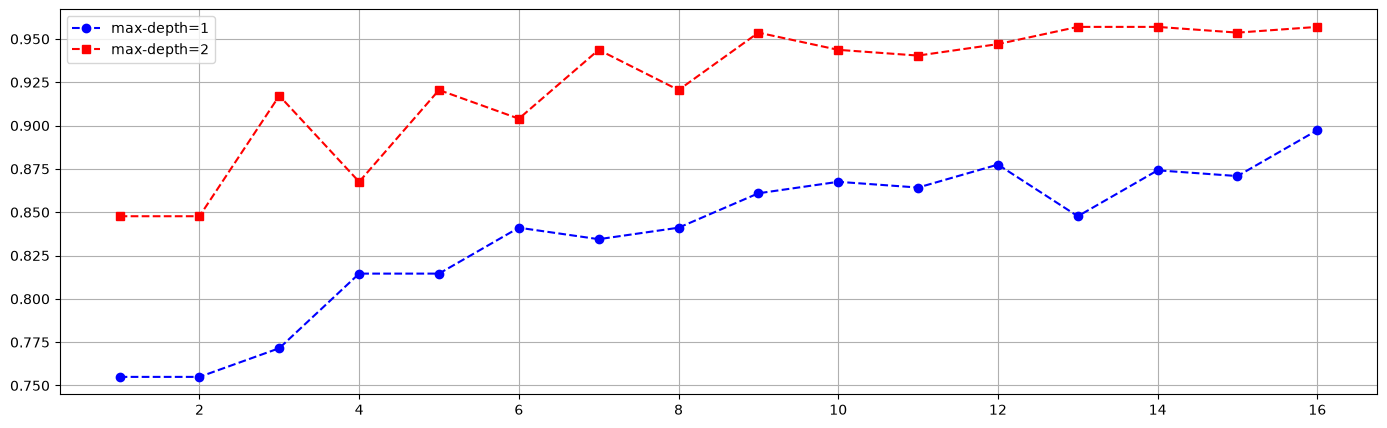

In [54]:
plt.figure(figsize=(17,5))
plt.plot(n_estimator,acc_depth_1,marker='o',linestyle='--',color='blue',label='max-depth=1')
plt.plot(n_estimator,acc_depth_2,marker='s',linestyle='--',color='red',label='max-depth=2')
plt.legend()
plt.grid(True)
plt.show()